In [ ]:
%pip install puremacro


# Pliegues, jacobianos singulares y continuación de Keller

**¿Cómo distinguimos si un solver de equilibrio falla en un pliegue, por un mal punto de partida o porque el equilibrio deja de existir, cuando se mueve un parámetro de política?**

Cuatro experimentos, cada uno con insumos etiquetados por lo que son:

| Experimento | Insumo | Oráculo |
|---|---|---|
| 1. Un pliegue de libro de texto | el residuo escrito a mano $F=(x_1^2-\lambda,\;x_2-x_1)$ | ramas en forma cerrada $x_1=\pm\sqrt\lambda$ (independiente, derivado a mano) |
| 2. El modelo de comercio de puremacro | una matriz de contabilidad social de dos países y dos sectores construida a mano; los números son sintéticos | Newton contra la continuación de Keller (interno: dos rutas de puremacro); el umbral de Hawkins-Simon contra los valores propios de NumPy de una matriz construida a mano (interno: misma calibración) |
| 3. El certificado de existencia a escala | una tabla insumo-producto sintética con semilla, de 60 países por 12 sectores (`synthetic_icio_table(60, 12, seed=0)`); extracciones aleatorias genéricas, no un modelo de ninguna economía | las cotas de Collatz-Wielandt, que se certifican a sí mismas (interno); los valores propios de NumPy de la misma matriz (interno) |
| 4. Un paso lineal rígido | una matriz aleatoria de 60x60 con una coordenada rígida plantada (semilla 42) | el residuo de cada paso devuelto, recalculado (interno) |

El ejercicio final usa la curva de Laffer, cuyo máximo $t^*=1/(1+\varepsilon)$ se conoce en forma cerrada.

## El método en matemáticas

Escribe las condiciones de equilibrio como $F(x,\lambda)=0$, $x\in\mathbb R^n$, con un parámetro escalar $\lambda$ (una trayectoria arancelaria, una meta de recaudación). Un **pliegue** (punto de retorno, o bifurcación silla-nodo) es una solución donde $F_x$ es singular y la rama da la vuelta en $\lambda$. La **continuación en el parámetro natural** fija $\lambda$ y aplica Newton en $x$, $x^{k+1}=x^k-F_x^{-1}F(x^k,\lambda)$, así que más allá de un pliegue no tiene raíz que encontrar. La **continuación por pseudo-longitud de arco de Keller (PAC)** convierte $\lambda$ en incógnita y avanza una distancia $\Delta s$ a lo largo de la tangente unitaria $t=(t_x,t_\lambda)$:

$$\underbrace{\begin{pmatrix}F_x & F_\lambda\\ t_{x}^{\top} & t_{\lambda}\end{pmatrix}}_{\text{matriz orlada}}t^{\text{nueva}}=\begin{pmatrix}0\\1\end{pmatrix},\qquad (\hat x,\hat\lambda)=(x_k,\lambda_k)+\Delta s\,t\quad\text{(predictor)},$$

$$\text{corrector: Newton sobre}\quad G(x,\lambda)=\begin{pmatrix}F(x,\lambda)\\ t_x^{\top}(x-x_k)+t_\lambda(\lambda-\lambda_k)-\Delta s\end{pmatrix}=0,\ \text{cuyo jacobiano es la matriz orlada.}$$

En un pliegue simple $F_x$ pierde una dirección, pero $F_\lambda$ queda fuera de su imagen, de modo que la matriz orlada sigue siendo invertible mientras $t_\lambda$ pasa por cero: **un pliegue es un cambio de signo de $t_\lambda$**. En el ejemplo de juguete, $\det F_x=2x_1$ y $\kappa(F_x)\propto 1/|x_1|$ cerca del pliegue en $\lambda=0$.

**Existencia.** Con insumos intermedios Leontief, los precios de costo unitario resuelven $p^\top=p^\top B_\tau+v^\top$ con $B_{\tau,ij}=a_{ij}\,m_{ij}/(1-t_j)$, donde $m_{ij}=1+\tau$ en los flujos transfronterizos, $t_j$ es el impuesto a la producción y $v>0$ reúne los costos unitarios de los factores. Existe un vector de precios positivo si y solo si $\rho(B_\tau)<1$ (Hawkins-Simon); entonces existe para todo $v>0$, pero nada en la condición dice que los precios de los factores que un equilibrio necesita sigan siendo positivos. Para cualquier $u>0$, $\min_i (B_\tau u)_i/u_i\le\rho(B_\tau)\le\max_i (B_\tau u)_i/u_i$ (Collatz-Wielandt): una cota superior menor que uno certifica la productividad, una cota inferior de al menos uno certifica el fracaso, y un intervalo que contiene al uno no prueba nada.

## Intuición

**Intuición.** Piensa en $\lambda$ como una perilla de política y en $x$ como el equilibrio que produce. A lo largo de una rama suave, un giro pequeño de la perilla mueve poco el equilibrio, así que arrancar Newton desde la última solución funciona. En un pliegue la rama da la vuelta: más allá no hay un equilibrio cercano, y en el pliegue el jacobiano pierde una dirección, de modo que Newton pasa de convergencia cuadrática a lineal. PAC deja de tratar la perilla como dada y camina sobre la curva de soluciones; la columna $F_\lambda$ aporta la dirección que $F_x$ perdió. La curva de Laffer es el prototipo económico: ninguna tasa impositiva recauda más que el máximo, y una trayectoria de metas de recaudación crecientes da la vuelta en el máximo hacia el lado de impuestos altos. Pero no toda falla es un pliegue. Un solver puede fallar porque arranca demasiado lejos de la respuesta (cualquier continuación lo corrige), o porque el equilibrio deja de existir en una frontera donde un precio llega a cero. Un monitor de pliegues tiene que distinguir estos casos, y un certificado como el de Hawkins-Simon solo descarta algunos.

## Código resuelto

El preámbulo carga el estilo de las figuras y los solvers de comercio. El generador aleatorio solo lo usa el experimento 4.

In [1]:
import re
import sys
import warnings
from pathlib import Path

import numpy as np
import scipy.linalg as la
import matplotlib.pyplot as plt
from scipy.optimize import brentq

_cwd = Path.cwd()
sys.path.insert(0, str(_cwd if (_cwd / "_nbstyle.py").exists() else _cwd / "notebooks"))
import _nbstyle
_nbstyle.apply_style()

from puremacro.trade import calibrate_trade_model, compute_equilibrium_residuals, solve_trade_equilibrium
from puremacro.trade.data import synthetic_icio_table
from puremacro.trade.solver import (
    check_hawkins_simon_viability,
    clamp_wage_displacement,
    solve_fold_continuation_step,
    solve_keller_pac,
    svd_clamped_newton_step,
)

rng = np.random.default_rng(42)

### Experimento 1: un pliegue de libro de texto

Dos funciones auxiliares sirven a todo el cuaderno: Newton con $\lambda$ fija, y PAC. `pac` registra la componente $\lambda$ de la tangente unitaria en cada nodo, incluido el inicial, para que la prueba del pliegue busque un cambio de signo y no un valor negativo.

In [2]:
def newton_fixed(F, Fx, x0, lam, max_iter=50, tol=1e-10):
    """Newton in x with lam held fixed. Returns the last iterate, success, and the path of x[0]."""
    x = np.array(x0, dtype=float)
    path = [x[0]]
    for _ in range(max_iter):
        f, J = F(x, lam), Fx(x, lam)
        if not (np.all(np.isfinite(f)) and np.all(np.isfinite(J))):
            return x, False, np.array(path)                      # el iterado salió del dominio de F
        if np.max(np.abs(f)) < tol:
            return x, True, np.array(path)
        try:
            x = x - la.solve(J, f)
        except la.LinAlgError:                                   # jacobiano exactamente singular
            return x, False, np.array(path)
        path.append(x[0])
    return x, bool(np.max(np.abs(F(x, lam))) < tol), np.array(path)


def pac(F, Fx, Flam, x0, lam0, ds, n_steps, lam_direction, until=None, tol=1e-12):
    """Keller pseudo-arclength continuation of F(x, lam) = 0 from the solution (x0, lam0)."""
    def bordered(z, t):
        x, lam = z[:-1], z[-1]
        return np.block([[Fx(x, lam), Flam(x, lam)[:, None]], [t[None, :]]])

    z = np.r_[x0, lam0]
    # Primera tangente: el vector nulo de [F_x, F_lam], orientado hacia donde debe moverse lam.
    t = la.null_space(np.column_stack([Fx(z[:-1], z[-1]), Flam(z[:-1], z[-1])]))[:, 0]
    t = t if np.sign(t[-1]) == np.sign(lam_direction) else -t
    rec = {"z": [z.copy()], "t_lam": [t[-1]], "cond_Fx": [np.linalg.cond(Fx(z[:-1], z[-1]))],
           "cond_bordered": [np.linalg.cond(bordered(z, t))], "max_F": [np.max(np.abs(F(z[:-1], z[-1])))]}
    for _ in range(n_steps):
        zk = z + ds * t                                          # predictor
        for _ in range(20):                                      # corrector
            g = np.r_[F(zk[:-1], zk[-1]), t @ (zk - z) - ds]
            if np.max(np.abs(g)) < tol:
                break
            zk = zk - la.solve(bordered(zk, t), g)
        t = la.solve(bordered(zk, t), np.eye(len(z))[-1])     # nueva tangente, t_vieja . t_nueva > 0
        t /= np.linalg.norm(t)
        z = zk
        rec["z"].append(z.copy())
        rec["t_lam"].append(t[-1])
        rec["cond_Fx"].append(np.linalg.cond(Fx(z[:-1], z[-1])))
        rec["cond_bordered"].append(np.linalg.cond(bordered(z, t)))
        rec["max_F"].append(np.max(np.abs(F(z[:-1], z[-1]))))
        if until is not None and until(z):
            break
    return {key: np.array(val) for key, val in rec.items()}


def F_toy(x, lam):
    return np.array([x[0] ** 2 - lam, x[1] - x[0]])


def Fx_toy(x, lam):
    return np.array([[2.0 * x[0], 0.0], [-1.0, 1.0]])


def Flam_toy(x, lam):
    return np.array([-1.0, 0.0])


# Continuación en el parámetro natural: bajar lam paso a paso, arrancando Newton en la última solución.
natural = []
x_warm = np.array([0.2, 0.2])
for lam in (0.03, 0.02, 0.01, 0.0, -0.01):
    x_new, ok, path = newton_fixed(F_toy, Fx_toy, x_warm, lam)
    natural.append({"lam": lam, "ok": ok, "iters": len(path) - 1, "x1": x_new[0],
                    "max_F": np.max(np.abs(F_toy(x_new, lam))), "path": path})
    if ok:
        x_warm = x_new
    print(f"lam = {lam:+.2f}: converged {ok!s:5}  iterations {len(path) - 1:2d}  "
          f"x1 = {x_new[0]:+.2e}  max|F| = {natural[-1]['max_F']:.1e}")

halving = natural[3]["path"][1:] / natural[3]["path"][:-1]
print(f"At lam = 0 all {len(halving)} Newton steps multiply x1 by {halving.mean():.6f}; "
      f"the state error {natural[3]['x1']:.1e} is the square root of the residual {natural[3]['max_F']:.1e}.")

assert [r["ok"] for r in natural] == [True, True, True, True, False], "Newton must succeed down to the fold and fail past it"
assert np.allclose(halving, 0.5, atol=1e-12), "at the singular root Newton is only linear, with ratio 1/2"
assert max(r["iters"] for r in natural[:3]) < natural[3]["iters"]

lam = +0.03: converged True   iterations  3  x1 = +1.73e-01  max|F| = 8.5e-11
lam = +0.02: converged True   iterations  4  x1 = +1.41e-01  max|F| = 6.9e-18
lam = +0.01: converged True   iterations  4  x1 = +1.00e-01  max|F| = 2.3e-14
lam = +0.00: converged True   iterations 14  x1 = +6.10e-06  max|F| = 3.7e-11
lam = -0.01: converged False  iterations 50  x1 = -6.89e-02  max|F| = 1.5e-02
At lam = 0 all 14 Newton steps multiply x1 by 0.500000; the state error 6.1e-06 is the square root of the residual 3.7e-11.


In [3]:
# PAC desde el mismo inicio, rumbo al pliegue (lam decreciente).
toy = pac(F_toy, Fx_toy, Flam_toy, np.array([0.2, 0.2]), 0.04, ds=0.08, n_steps=14, lam_direction=-1.0)
x1_pac, lam_pac = toy["z"][:, 0], toy["z"][:, -1]
sign_t = np.sign(toy["t_lam"])
flips = np.flatnonzero(np.diff(sign_t))
lower = x1_pac < 0
branch_err = np.max(np.abs(x1_pac[lower] + np.sqrt(lam_pac[lower])))

print("t_lambda at the nodes:", np.array2string(toy["t_lam"], precision=3, max_line_width=120))
assert sign_t[0] < 0 < sign_t[-1] and len(flips) == 1, f"t_lambda must change sign exactly once, not {len(flips)} times"
print(f"Sign changes of t_lambda: {len(flips)}, between nodes {flips[0]} and {flips[0] + 1} "
      f"(x1 from {x1_pac[flips[0]]:+.3f} to {x1_pac[flips[0] + 1]:+.3f}); smallest lambda visited {lam_pac.min():.1e}")
print(f"{lower.sum()} nodes on the lower branch, max|x1 + sqrt(lambda)| = {branch_err:.1e}; max|F| on the path {toy['max_F'].max():.1e}")
print(f"cond(F_x) at the nodes peaks at {toy['cond_Fx'].max():.3g}; the bordered matrix stays between "
      f"{toy['cond_bordered'].min():.3g} and {toy['cond_bordered'].max():.3g}")

# La prueba del pliegue: un cambio de signo (verificado arriba), en el cruce de x1 = 0, y el otro lado sobre la rama inferior.
assert x1_pac[flips[0]] > 0 > x1_pac[flips[0] + 1], "the sign change must coincide with x1 crossing zero"
assert lower.sum() >= 5 and branch_err < 1e-10, "the nodes past the fold must lie on x1 = -sqrt(lambda)"
assert lam_pac.min() >= 0.0 and toy["max_F"].max() < 1e-10

t_lambda at the nodes: [-0.272 -0.201 -0.125 -0.046  0.034  0.113  0.189  0.261  0.328  0.389  0.443  0.492  0.535  0.574  0.608]
Sign changes of t_lambda: 1, between nodes 3 and 4 (x1 from +0.033 to -0.024); smallest lambda visited 5.7e-04
11 nodes on the lower branch, max|x1 + sqrt(lambda)| = 2.5e-14; max|F| on the path 2.4e-14
cond(F_x) at the nodes peaks at 41.9; the bordered matrix stays between 1.42 and 1.78


On the dense branch: max cond(F_x) = 1.00e+06, bordered matrix between 1.41 and 1.85


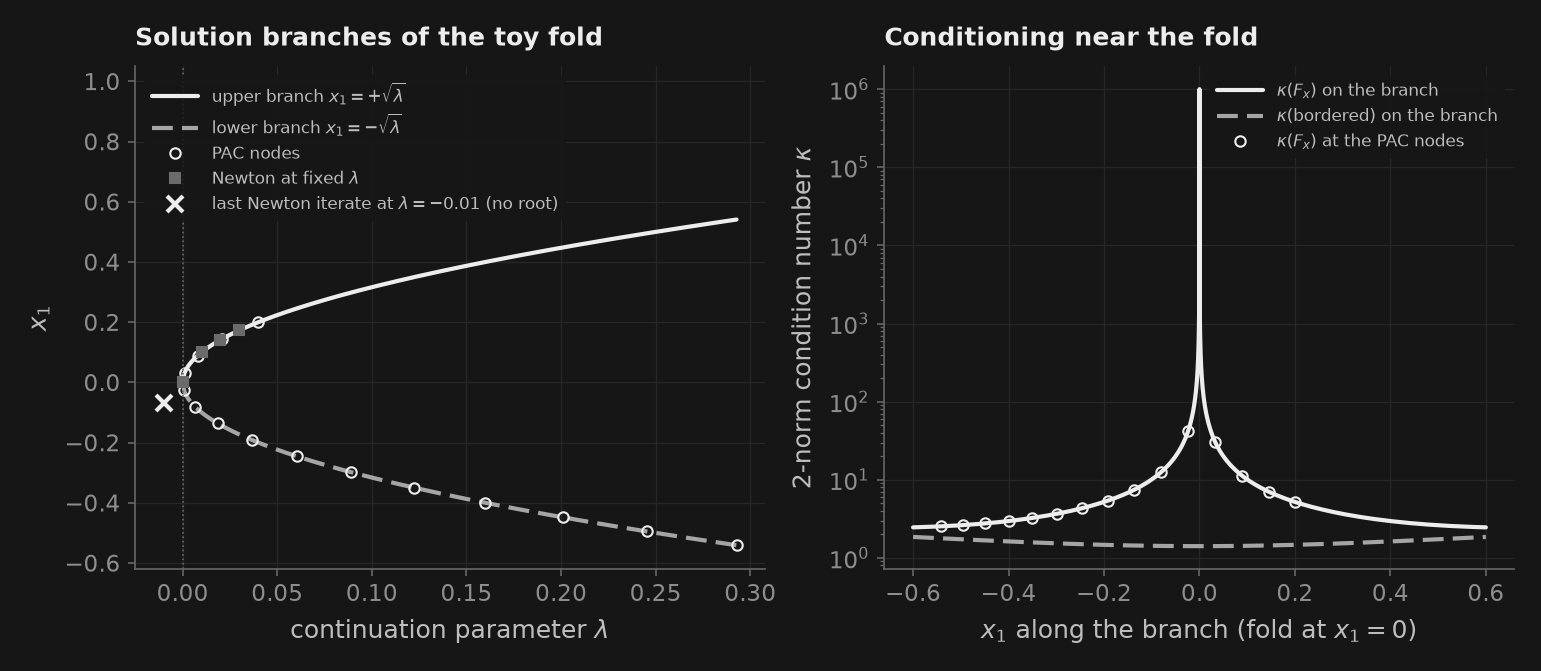

In [4]:
# Figura 1. Condicionamiento a lo largo de la rama analítica x = (s, s), lambda = s^2, en una malla que
# llega a |x1| = 1e-6: los 15 nodos de PAC son demasiado gruesos para mostrar la explosión por sí solos.
s_grid = np.r_[-np.logspace(np.log10(0.6), -6, 300), np.logspace(-6, np.log10(0.6), 300)]
cond_Fx_branch = np.array([np.linalg.cond(Fx_toy(np.array([s, s]), s * s)) for s in s_grid])
cond_bordered_branch = []
for s in s_grid:
    t_branch = np.array([1.0, 1.0, 2.0 * s]) / np.sqrt(2.0 + 4.0 * s * s)   # tangente unitaria de la rama
    J_b = np.block([[Fx_toy(np.array([s, s]), s * s), Flam_toy(None, None)[:, None]], [t_branch[None, :]]])
    cond_bordered_branch.append(np.linalg.cond(J_b))
cond_bordered_branch = np.array(cond_bordered_branch)
print(f"On the dense branch: max cond(F_x) = {cond_Fx_branch.max():.2e}, "
      f"bordered matrix between {cond_bordered_branch.min():.3g} and {cond_bordered_branch.max():.3g}")
assert cond_Fx_branch.max() > 1e5 and cond_bordered_branch.max() < 2.0

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
lam_line = np.linspace(0.0, lam_pac.max(), 300)
ax0.plot(lam_line, np.sqrt(lam_line), **_nbstyle.S1, label=r"upper branch $x_1=+\sqrt{\lambda}$")
ax0.plot(lam_line, -np.sqrt(lam_line), **_nbstyle.S2, label=r"lower branch $x_1=-\sqrt{\lambda}$")
ax0.plot(lam_pac, x1_pac, ls="none", marker="o", ms=5, mfc="none", mec=_nbstyle.TINTA, label="PAC nodes")
ok_runs = [r for r in natural if r["ok"]]
ax0.plot([r["lam"] for r in ok_runs], [r["x1"] for r in ok_runs], ls="none", marker="s", ms=5,
         color=_nbstyle.S3["color"], label=r"Newton at fixed $\lambda$")
failed = natural[-1]
ax0.plot(failed["lam"], failed["x1"], ls="none", marker="x", ms=8, mew=2, color=_nbstyle.TINTA,
         label=rf"last Newton iterate at $\lambda={failed['lam']:.2f}$ (no root)")
ax0.axvline(0.0, color=_nbstyle.SPINE, lw=0.8, ls=":")
ax0.set_xlabel(r"continuation parameter $\lambda$")
ax0.set_ylabel(r"$x_1$")
ax0.set_title("Solution branches of the toy fold")
ax0.set_ylim(-0.62, 1.05)
ax0.legend(loc="upper left", fontsize=8)

ax1.semilogy(s_grid, cond_Fx_branch, **_nbstyle.S1, label=r"$\kappa(F_x)$ on the branch")
ax1.semilogy(s_grid, cond_bordered_branch, **_nbstyle.S2, label=r"$\kappa$(bordered) on the branch")
ax1.plot(x1_pac, toy["cond_Fx"], ls="none", marker="o", ms=5, mfc="none", mec=_nbstyle.TINTA,
         label=r"$\kappa(F_x)$ at the PAC nodes")
ax1.set_xlabel(r"$x_1$ along the branch (fold at $x_1=0$)")
ax1.set_ylabel(r"2-norm condition number $\kappa$")
ax1.set_title("Conditioning near the fold")
ax1.legend(loc="upper right", fontsize=8)

### Experimento 2: el modelo de comercio de puremacro

Una matriz de contabilidad social construida a mano para dos países, A (`C00`) y B (`C01`), con dos sectores cada uno. Los números son sintéticos. Las cuentas de bienes cuadran; A importa más de lo que exporta, y la brecha se mantiene fija como ahorro externo.

In [5]:
nc_cge, ns_cge, nfd_cge = 2, 2, 3
data_cge = np.zeros((ns_cge * nc_cge + 3, ns_cge * nc_cge + nfd_cge * nc_cge))
data_cge[:4, :4] = np.array([[20.0, 10.0, 5.0, 2.0],
                             [8.0, 25.0, 2.0, 4.0],
                             [5.0, 5.0, 12.0, 18.0],
                             [10.0, 10.0, 18.0, 22.0]])
y_cge = np.array([100.0, 150.0, 120.0, 180.0])            # producción bruta por país-sector
va_fac = y_cge - data_cge[:4, :4].sum(axis=0) - 0.05 * y_cge
data_cge[4, :4] = 0.05 * y_cge                             # impuestos a la producción
data_cge[5, :4] = (2.0 / 3.0) * va_fac                     # las dos filas de factores
data_cge[6, :4] = (1.0 / 3.0) * va_fac
fd_rows = y_cge - data_cge[:4, :4].sum(axis=1)
home_bias, abroad = np.array([0.50, 0.25, 0.05]), np.array([0.10, 0.08, 0.02])
for i in range(4):
    split = np.r_[home_bias, abroad] if i < 2 else np.r_[abroad, home_bias]
    data_cge[i, 4:10] = fd_rows[i] * split
data_cge[4, 4:] = 0.02 * data_cge[:4, 4:].sum(axis=0)
calib_cge = calibrate_trade_model(data_cge, ns=ns_cge, nc=nc_cge, nfd=nfd_cge, validate=True)

exports_A = data_cge[0:2, [2, 3, 7, 8, 9]].sum()
imports_A = data_cge[2:4, [0, 1, 4, 5, 6]].sum()
print(f"A exports {exports_A:.1f} and imports {imports_A:.1f}; baseline foreign balances {calib_cge.invforT.ravel()}")

A exports 47.8 and imports 70.0; baseline foreign balances [-22.2  22.2]


**Donde el equilibrio deja de existir.** `solve_trade_equilibrium` usa contabilidad consistente ([docs/es/trade_accounting.md](../docs/es/trade_accounting.md)). Seguimos el equilibrio mientras sube el arancel, arrancando Newton en la solución anterior (continuación en el parámetro natural, el arancel), una vez con insumos intermedios Leontief ($\sigma=0$) y otra con elasticidad unitaria ($\sigma=1$). Registramos el precio de los factores de A relativo al de B, que no depende del numerario, y el menor valor singular del jacobiano $F_x$ en cada solución. Después pedimos a PAC un arancel más allá del final de cada trayectoria y leemos su monitor de pliegues.

In [6]:
def smallest_singular_value(x, tau, sigma, h=1e-7):
    """sigma_min of F_x at x, by central differences of the public residual function."""
    F = lambda z: compute_equilibrium_residuals(z, calib_cge, tau=tau, tau_fd=tau, sigma=sigma)
    J = np.column_stack([(F(x + h * e) - F(x - h * e)) / (2 * h) for e in np.eye(x.size)])
    return np.linalg.svd(J, compute_uv=False)[-1]


def tariff_path(sigma, taus):
    """Warm-started Newton along a tariff grid; stops at the first failure.

    Returns the tariffs reached, w_A / w_B and sigma_min(F_x) at each solution."""
    x, rel, smin = None, [], []
    for tau in taus:
        res = solve_trade_equilibrium(calib_cge, tau=tau, tau_fd=tau, sigma=sigma, x0=x, tol=1e-9)
        if not res.converged:
            break
        x = res.x_sol
        rel.append(res.w_sol.ravel()[0] / res.w_sol.ravel()[1])
        smin.append(smallest_singular_value(x.ravel(), tau, sigma))
    return np.asarray(taus[: len(rel)]), np.asarray(rel), np.asarray(smin)


tau_leo, rel_leo, smin_leo = tariff_path(0.0, np.r_[np.arange(0.0, 4.2, 0.05), np.arange(4.2, 4.3, 0.005)])
tau_sub, rel_sub, smin_sub = tariff_path(1.0, np.r_[np.arange(0.0, 1.05, 0.05), np.arange(1.05, 1.1, 0.0025)])
tau_zero = np.polyval(np.polyfit(rel_leo[-4:], tau_leo[-4:], 1), 0.0)   # where w_A / w_B reaches 0

with warnings.catch_warnings():         # silence overflow warnings while log w_A heads to -infinity
    warnings.simplefilter("ignore", RuntimeWarning)
    stall = solve_keller_pac(calib_cge, tau_target=4.4, sigma=0.0, tol=1e-9)
tau_stall = 4.4 * stall.metadata["final_lambda"]
turn = solve_keller_pac(calib_cge, tau_target=1.1, sigma=1.0, tol=1e-9)
event = turn.metadata["fold_points"][0]

print(f"sigma = 0: w_A/w_B = {rel_leo[0]:.3f} at 0%, {rel_leo[np.argmin(np.abs(tau_leo - 4.0))]:.3f} at 400%, "
      f"{rel_leo[-1]:.5f} at {tau_leo[-1]:.1%}; linear extrapolation reaches zero at a tariff of {tau_zero:.4f}")
print(f"  sigma_min(F_x) from {smin_leo[0]:.1e} at 0% to {smin_leo[-1]:.1e} at the last solution")
print(f"  PAC to 440%: converged {stall.converged}, stalls at an effective tariff of {tau_stall:.4f}, "
      f"fold events {len(stall.metadata['fold_points'])}, raw detections {stall.metadata['fold_detections']}")
print(f"sigma = 1: last solution at {tau_sub[-1]:.4f} with w_A/w_B = {rel_sub[-1]:.3f}; "
      f"sigma_min(F_x) falls from {smin_sub[0]:.1e} to {smin_sub[-1]:.1e}")
print(f"  PAC to 110%: converged {turn.converged}; fold monitor: {len(turn.metadata['fold_points'])} event of kind "
      f"'{event['kind']}', first detected at an effective tariff of {1.1 * event['lambda']:.4f}, "
      f"lambda reversed: {event['lambda_reversed']}, smallest log factor price {event['min_log_factor_price']:.2f}")

assert (not stall.converged) and stall.metadata["fold_points"] == [], "a corner: no fold event"
assert abs(tau_zero - tau_stall) < 0.01, "the warm-started path and PAC must locate the same boundary"
assert rel_leo[-1] < 1e-3 and rel_sub[-1] > 0.1, "sigma = 0 ends at a zero factor price, sigma = 1 does not"
assert smin_sub[-1] < 0.05 * smin_sub[0], "sigma = 1: the Jacobian becomes nearly singular where the path ends"
assert (not turn.converged) and event["kind"] == "lambda_reversal" and event["lambda_reversed"]

sigma = 0: w_A/w_B = 1.000 at 0%, 0.076 at 400%, 0.00032 at 425.0%; linear extrapolation reaches zero at a tariff of 4.2510
  sigma_min(F_x) from 1.4e-02 at 0% to 2.9e-05 at the last solution
  PAC to 440%: converged False, stalls at an effective tariff of 4.2510, fold events 0, raw detections 0
sigma = 1: last solution at 1.0775 with w_A/w_B = 0.187; sigma_min(F_x) falls from 3.1e-03 to 2.3e-05
  PAC to 110%: converged False; fold monitor: 1 event of kind 'lambda_reversal', first detected at an effective tariff of 1.0369, lambda reversed: True, smallest log factor price -0.98


**Qué dice el certificado de existencia en esta tabla.** Buscamos el arancel en el que falla el certificado de Hawkins-Simon, por bisección sobre la verificación pública (lanza `ValueError` cuando un esquema no queda certificado; la función auxiliar lee el veredicto y las cotas en el mensaje). Lo comprobamos por una segunda ruta: los valores propios de NumPy de $B_\tau$ construida a mano a partir de la calibración.

In [7]:
def hawkins_simon(calib, tau):
    """('viable' | 'violated' | 'unresolved' | 'error', lower bound, upper bound) from the public check."""
    try:
        cert = check_hawkins_simon_viability(calib, tau=tau)
        return "viable", cert.cw_lower, cert.cw_upper
    except ValueError as err:
        msg = str(err)
        status = "violated" if "violates" in msg else "unresolved" if "unresolved" in msg else "error"
        found = re.findall(r"\[([-+0-9.eE]+), ([-+0-9.eE]+)\]", msg)
        low, high = (float(found[0][0]), float(found[0][1])) if found else (np.nan, np.nan)
        return status, low, high


def hs_threshold(calib, lo, hi, tol):
    """Bisect between a certified-viable and a certified-violated tariff."""
    assert hawkins_simon(calib, lo)[0] == "viable" and hawkins_simon(calib, hi)[0] == "violated"
    while hi - lo > tol:
        mid = 0.5 * (lo + hi)
        status = hawkins_simon(calib, mid)[0]
        assert status in ("viable", "violated"), f"certificate {status} at {mid}"
        lo, hi = (mid, hi) if status == "viable" else (lo, mid)
    return lo, hi


def B_by_hand(calib, tau):
    """B_tau = a * m / (1 - t) with m = 1 + tau across borders; taxes clipped as the public check does."""
    ns, nc = calib.n_sectors, calib.n_countries
    a = np.asarray(calib.a, dtype=float).reshape((ns * nc, ns * nc), order="F")
    tax = np.clip(np.asarray(calib.tax, dtype=float).flatten(order="F"), -0.9, 0.999)
    country = np.arange(ns * nc) // ns
    m = np.where(country[:, None] != country[None, :], 1.0 + tau, 1.0)
    return a * m / (1.0 - tax)[None, :]


hs_lo, hs_hi = hs_threshold(calib_cge, 0.0, 20.0, tol=1e-6)
tau_eig = brentq(lambda tau: np.max(np.abs(np.linalg.eigvals(B_by_hand(calib_cge, tau)))) - 1.0, 0.0, 20.0, xtol=1e-9)
status_stall, low_stall, high_stall = hawkins_simon(calib_cge, tau_stall)
taus_cert = np.linspace(0.0, 10.0, 101)
rho_upper = np.array([check_hawkins_simon_viability(calib_cge, tau=t).cw_upper if t < hs_lo
                      else np.nan for t in taus_cert])
print(f"Certificate threshold on the 2x2 table: between {hs_lo:.6f} and {hs_hi:.6f}; eigenvalue route {tau_eig:.6f}")
print(f"At {tau_stall:.0%}, where the sigma = 0 branch ends: {status_stall}, rho(B) in [{low_stall:.4f}, {high_stall:.4f}]")

assert abs(0.5 * (hs_lo + hs_hi) - tau_eig) < 1e-4, "the certificate and the eigenvalues must agree"
assert status_stall == "viable" and high_stall < 0.9, "Hawkins-Simon certifies prices where the branch ends"

Certificate threshold on the 2x2 table: between 8.653800 and 8.653801; eigenvalue route 8.653814
At 425%, where the sigma = 0 branch ends: viable, rho(B) in [0.6638, 0.6638]


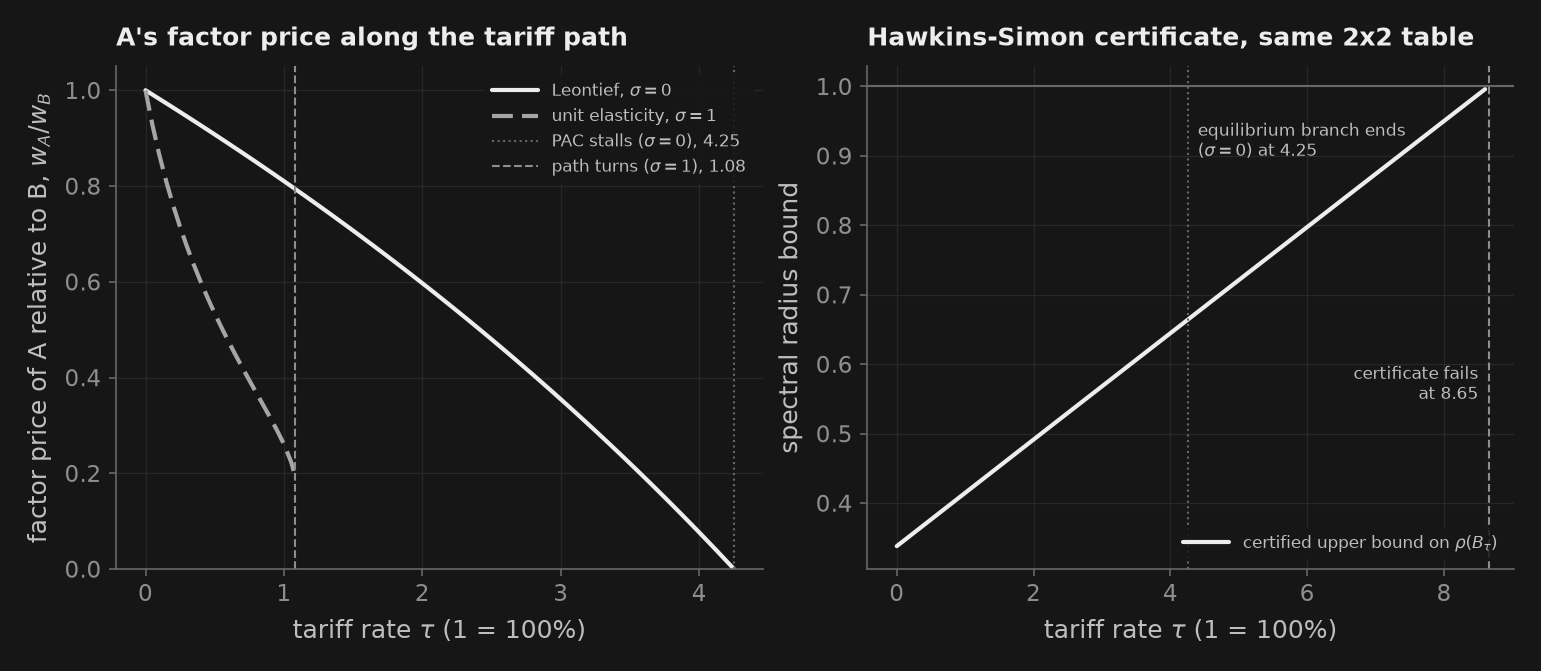

In [8]:
# Figura 2. Izquierda: precio relativo de los factores de A a lo largo del arancel. Derecha: el certificado en la misma tabla.
fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(10, 4.2), layout="constrained")
ax0.plot(tau_leo, rel_leo, **_nbstyle.S1, label=r"Leontief, $\sigma=0$")
ax0.plot(tau_sub, rel_sub, **_nbstyle.S2, label=r"unit elasticity, $\sigma=1$")
ax0.axvline(tau_stall, color=_nbstyle.SPINE, lw=1.0, ls=":", label=rf"PAC stalls ($\sigma=0$), {tau_stall:.2f}")
ax0.axvline(tau_sub[-1], color=_nbstyle.NOTA, lw=1.0, ls="--", label=rf"path turns ($\sigma=1$), {tau_sub[-1]:.2f}")
ax0.set_xlabel(r"tariff rate $\tau$ (1 = 100%)")
ax0.set_ylabel(r"factor price of A relative to B, $w_A/w_B$")
ax0.set_title("A's factor price along the tariff path")
ax0.set_ylim(bottom=0.0)
ax0.legend(loc="upper right", fontsize=8)

ax1.plot(taus_cert, rho_upper, **_nbstyle.S1, label=r"certified upper bound on $\rho(B_\tau)$")
ax1.axhline(1.0, color=_nbstyle.SPINE, lw=1.0, ls="-")
ax1.axvline(tau_stall, color=_nbstyle.SPINE, lw=1.0, ls=":")
ax1.axvline(tau_eig, color=_nbstyle.NOTA, lw=1.0, ls="--")
ax1.text(tau_stall + 0.15, 0.95, "equilibrium branch ends\n" rf"($\sigma=0$) at {tau_stall:.2f}",
         color=_nbstyle.TEXTO, fontsize=8, va="top")
ax1.text(tau_eig - 0.15, 0.55, f"certificate fails\nat {tau_eig:.2f}", color=_nbstyle.TEXTO, fontsize=8, ha="right")
ax1.set_xlabel(r"tariff rate $\tau$ (1 = 100%)")
ax1.set_ylabel(r"spectral radius bound")
ax1.set_title("Hawkins-Simon certificate, same 2x2 table")
ax1.legend(loc="lower right", fontsize=8)

### Experimento 3: el certificado a escala

Una tabla sintética con semilla, de 60 países y 12 sectores, da una matriz $B_\tau$ de 720 filas; sus flujos son extracciones aleatorias genéricas, así que los números describen al generador, no a una red de producción. La verificación pública recorta las tasas del impuesto a la producción a $[-0.9, 0.999]$, así que las cotas corresponden a esa matriz recortada (en esta tabla no se recorta ninguna tasa). Los valores propios de NumPy de la matriz construida a mano comprueban el umbral.

In [9]:
nc_big, ns_big = 60, 12
calib_big = calibrate_trade_model(synthetic_icio_table(nc_big, ns_big, seed=0), ns=ns_big, nc=nc_big, nfd=3,
                                  validate=True)
codes = list(calib_big.country_codes)
n_clipped = int(np.sum(np.asarray(calib_big.tax) < -0.9))
print(f"{len(codes)} synthetic countries ({codes[0]} to {codes[-1]}), {calib_big.n_sectors * len(codes)} "
      f"country-sectors; {n_clipped} tax rates below -0.9 are clipped")
big = {tau: hawkins_simon(calib_big, tau) for tau in (0.0, 0.25, 8.0)}
for tau, (status, low, high) in big.items():
    print(f"tariff {tau:4.0%}: {status:9s} rho(B) in [{low:.6f}, {high:.6f}]")
big_lo, big_hi = hs_threshold(calib_big, 4.0, 8.0, tol=1e-5)
print(f"The certificate switches from viable to violated between tariffs of {big_lo:.5f} and {big_hi:.5f}")
tau_eig_big = brentq(lambda tau: np.max(np.abs(np.linalg.eigvals(B_by_hand(calib_big, tau)))) - 1.0,
                     big_lo - 0.01, big_hi + 0.01, xtol=1e-9)
print(f"NumPy's eigenvalues of the {B_by_hand(calib_big, 0.0).shape[0]}-row matrix put rho(B) = 1 at {tau_eig_big:.6f}")

assert big[0.25][0] == "viable" and big[0.25][2] < 1.0, "the upper bound, not an estimate, certifies"
assert big[8.0][0] == "violated" and big[8.0][1] >= 1.0, "800% must be a certified violation, not unresolved"
assert big_lo - 1e-3 < tau_eig_big < big_hi + 1e-3, "the certificate and the eigenvalues must agree"

60 synthetic countries (C01 to C60), 720 country-sectors; 0 tax rates below -0.9 are clipped
tariff   0%: viable    rho(B) in [0.445882, 0.445882]
tariff  25%: viable    rho(B) in [0.465500, 0.465500]
tariff 800%: violated  rho(B) in [1.085275, 1.085275]


The certificate switches from viable to violated between tariffs of 6.93586 and 6.93587


NumPy's eigenvalues of the 720-row matrix put rho(B) = 1 at 6.935878


### Experimento 4: ¿qué compra un paso de Newton acotado?

`puremacro.trade.solver` incluye tres funciones auxiliares que acotan un paso de Newton para los precios de los factores en logaritmos (`svd_clamped_newton_step`, `clamp_wage_displacement`, `solve_fold_continuation_step`); los solvers de la biblioteca no las llaman. Una cota evita que una mala linealización lance el iterado lejos. Aquí la dificultad es el propio sistema lineal: una matriz simétrica aleatoria del tamaño de la lista de países del experimento 3, con una fila y una columna escaladas por $10^{-5}$. La coordenada rígida es el país `C09`; la matriz es aleatoria y no dice nada sobre ese país. `solve_fold_continuation_step` elimina exactamente las otras 59 coordenadas, escala todo el paso hasta `max_disp` e informa el residuo del paso que devuelve.

In [10]:
n = len(codes)
k_stiff = codes.index("C09")
A_rnd = rng.standard_normal((n, n))
S = A_rnd.T @ A_rnd + np.eye(n)
S[k_stiff, :] *= 1e-5
S[:, k_stiff] *= 1e-5
S[k_stiff, k_stiff] = 1e-6
rhs = rng.standard_normal(n)


def rel_residual(step):
    return np.linalg.norm(S @ step - rhs) / np.linalg.norm(rhs)


dw_exact = la.solve(S, rhs)
dw_block, res_block, conv_block, info = solve_fold_continuation_step(
    S, rhs, idx_stiff="C09", country_codes=codes, max_disp=0.30, return_info=True)
steps = {
    "exact solve": dw_exact,
    "SVD modal clamp, then scale to 0.30": svd_clamped_newton_step(S, -rhs, np.ones(n), np.ones(n), max_comp=20.0, max_disp=0.30),
    "block elimination, then scale to 0.30": dw_block,
    "clip each coordinate to 0.30": clamp_wage_displacement(dw_exact, 0.30),
    "no step": np.zeros(n),
}
print(f"cond(S) = {np.linalg.cond(S):.2e}; stiff coordinate {info['idx_stiff']} ({info['country']}); "
      f"the exact solve has relative residual {rel_residual(dw_exact):.1e}")
for name, step in steps.items():
    print(f"  {name:38s} max|step| = {np.max(np.abs(step)):9.3g}   ||S step - rhs|| / ||rhs|| = {rel_residual(step):.4f}")
cosine = dw_block @ dw_exact / (np.linalg.norm(dw_block) * np.linalg.norm(dw_exact))
print(f"solve_fold_continuation_step reports residual {res_block:.4g} and converged {conv_block}; "
      f"its step is the exact solve times {info['clamp_scale']:.3g} (cosine {cosine:.6f}); "
      f"before the clamp the residual was {info['direction_residual']:.1e}")
print(f"Capped at 0.30 per step, Newton would need about {np.max(np.abs(dw_exact)) / 0.30:.2e} steps to cover the exact step")

assert rel_residual(dw_exact) < 1e-12 and info["idx_stiff"] == k_stiff and info["country"] == "C09"
assert abs(res_block - np.max(np.abs(S @ dw_block - rhs))) < 1e-12 and not conv_block, "reported = actual residual"
assert cosine > 1 - 1e-12 and info["direction_converged"]
assert 0.9 < rel_residual(steps["SVD modal clamp, then scale to 0.30"]) < 1.0
assert rel_residual(dw_block) > 0.999 and rel_residual(steps["clip each coordinate to 0.30"]) > 1.0

cond(S) = 2.23e+08; stiff coordinate 8 (C09); the exact solve has relative residual 4.1e-14
  exact solve                            max|step| =  7.91e+05   ||S step - rhs|| / ||rhs|| = 0.0000
  SVD modal clamp, then scale to 0.30    max|step| =       0.3   ||S step - rhs|| / ||rhs|| = 0.9852
  block elimination, then scale to 0.30  max|step| =       0.3   ||S step - rhs|| / ||rhs|| = 1.0000
  clip each coordinate to 0.30           max|step| =       0.3   ||S step - rhs|| / ||rhs|| = 13.4200
  no step                                max|step| =         0   ||S step - rhs|| / ||rhs|| = 1.0000
solve_fold_continuation_step reports residual 2.418 and converged False; its step is the exact solve times 3.79e-07 (cosine 1.000000); before the clamp the residual was 2.7e-13
Capped at 0.30 per step, Newton would need about 2.64e+06 steps to cover the exact step


## Lectura de los resultados

- **El pliegue de juguete (figura 1).** Newton con $\lambda$ fija, arrancado desde la solución anterior, converge en $\lambda=0.03$, $0.02$ y $0.01$ en 3 o 4 iteraciones. En el pliegue, $\lambda=0$, necesita 14: cada paso multiplica $x_1$ exactamente por 0.5, de modo que el estado sigue desviado en 6.1e-06 cuando el residuo es 3.7e-11. En $\lambda=-0.01$ falla porque no hay raíz real. PAC, desde el mismo punto, rodea el pliegue: $t_\lambda$ cambia de signo una vez, entre los nodos 3 y 4, donde $x_1$ cruza el cero (+0.033 a -0.024), y los 11 nodos posteriores están sobre $x_1=-\sqrt\lambda$ con un error de 2.5e-14. El panel derecho explica por qué funciona. A lo largo de la rama, $\kappa(F_x)$ crece como $1/|x_1|$, hasta 1.00e+06 en $|x_1|=10^{-6}$, mientras la matriz orlada se mantiene entre 1.41 y 1.85. Los nodos de PAC nunca se acercan al pliegue más que $|x_1|=0.024$, así que $\kappa(F_x)$ en los nodos llega apenas a 41.9: una trayectoria gruesa puede saltarse una singularidad sin verla, y por eso la prueba es el signo de $t_\lambda$ y no el tamaño de $\kappa$.
- **Donde termina el equilibrio (figura 2, izquierda).** Con contabilidad consistente, Newton con arranque en caliente sigue ambas trayectorias hasta su final. Con $\sigma=0$, el precio de los factores de A relativo al de B cae de 1.000 en 0% a 0.076 en 400% y a 0.00032 en 425%. Extrapolado linealmente llega a cero en un arancel de 4.2510, y PAC, al que se pide 440%, se detiene en 4.2510 sin ningún evento de pliegue ni ninguna detección. La rama de equilibrios termina donde el precio de los factores de A llega a cero: una esquina, no un pliegue. Con sustitución entre insumos ($\sigma=1$) la trayectoria termina mucho antes, en 107.75%, con $w_A/w_B$ todavía en 0.187: el precio de los factores está lejos de cero, pero el menor valor singular de $F_x$ cae de 3.1e-03 a 2.3e-05. PAC, al que se pide 110%, registra un evento de tipo `lambda_reversal`, detectado por primera vez en un arancel efectivo de 1.0369, y no converge: $\lambda$ baja, como en un punto de retorno, y más allá esta rama no tiene equilibrio. Ambos finales vuelven casi singular a $F_x$ ($\sigma_{\min}$ también cae a 2.9e-05 con $\sigma=0$), así que el tamaño de $\sigma_{\min}$ por sí solo no distingue una esquina de un pliegue; el precio de los factores y el signo de $t_\lambda$ sí.
- **Lo que el certificado puede y no puede decir (figura 2, derecha, y experimento 3).** En la tabla 2x2, el certificado de Hawkins-Simon se sostiene hasta un arancel entre 8.653800 y 8.653801; los valores propios de NumPy ubican $\rho(B_\tau)=1$ en 8.653814, un poco más arriba, porque el certificado exige una cota superior menor que $1-10^{-6}$. En 425%, donde termina la rama con $\sigma=0$, certifica $\rho(B)$ = 0.6638, y también se sostiene en la vuelta con $\sigma=1$. La condición es necesaria para precios Leontief positivos; está lejos de ser suficiente para un equilibrio con precios de los factores positivos. En la tabla sintética de 720 filas, un arancel de 25% mueve las cotas de 0.445882 a 0.465500, el veredicto cambia entre aranceles de 6.93586 y 6.93587 (valores propios de NumPy: 6.935878), y 800% es una violación certificada (ambas cotas en 1.085275), no un intervalo sin resolver. Estos números describen una tabla aleatoria, no una red de producción.
- **El paso rígido.** La solución exacta tiene un residuo relativo de 4.1e-14, pero mueve la coordenada rígida en 7.91e+05. Cada paso acotado a 0.30 deja casi todo el lado derecho sin explicar: el recorte modal por SVD deja un residuo relativo de 0.9852, la eliminación por bloques seguida de un escalamiento uniforme deja 1.0000 (lo mismo que no moverse, porque ese paso es la solución exacta multiplicada por 3.79e-07), y recortar cada coordenada lo eleva a 13.4200. `solve_fold_continuation_step` lo informa: residuo 2.418 y converged False para el paso que devuelve, mientras la dirección sin recortar tenía residuo 2.7e-13. Una cota limita un paso; no resuelve un sistema rígido, y a 0.30 por paso Newton necesitaría unos 2.64e+06 pasos. Una cota solo rinde cuando el modelo es no lineal y un paso largo saldría de la región donde vale la linealización, algo que esta prueba lineal no puede mostrar.

## Tu turno

Cambia la elasticidad de la base gravable $\varepsilon$. La recaudación es $R(t)=t(1-t)^{\varepsilon}$ para una tasa $t\in[0,1]$, así que el máximo de la curva de Laffer está en $t^*=1/(1+\varepsilon)$, una forma cerrada derivada a mano. La celda continúa la meta de recaudación $\bar R$ hacia arriba desde $t=0.05$ con la función `pac` del cuaderno y verifica tres cosas: la única vuelta de la trayectoria encierra a $t^*$, ningún nodo pide más que la recaudación máxima, y Newton para una meta 1% por encima del máximo no encuentra ninguna tasa en $[0,1]$.

1. **Básico.** Antes de ejecutar, predice $t^*$ para $\varepsilon=1$ y $\varepsilon=4$; luego ejecuta ambos casos. ¿Por qué el máximo de recaudación es un pliegue de la ecuación $R(t)=\bar R$, y qué registra el signo de $t_\lambda$ a lo largo de esta trayectoria?
2. **Intermedio.** En una celda nueva, ejecuta `newton_fixed(F_laffer, Fx_laffer, np.array([0.5 * t_star]), 0.99 * R_max)`. Ahora Newton converge: ¿de qué lado del máximo, si arranca en $t^*/2$, donde $R$ es cóncava? ¿Qué tasa recauda lo mismo del otro lado, y qué parte de la trayectoria de PAC la alcanza?
3. **Reto.** De vuelta en el experimento 2, ejecuta `tariff_path(0.5, np.arange(0.0, 4.5, 0.01))` y después `solve_keller_pac` con `sigma=0.5` y una meta un poco más allá del último arancel que alcanza la trayectoria. ¿El final de la rama con $\sigma=0.5$ es una esquina, como con $\sigma=0$ (un precio de los factores que va a cero, sin eventos de pliegue), o una vuelta, como con $\sigma=1$ (un evento `lambda_reversal` con precios de los factores lejos de cero)? ¿Qué números de la salida lo deciden?

In [11]:
eps_base = 2.0   # ← cambia esto: elasticidad de la base gravable, de 0.5 a 4
assert 0.5 <= eps_base <= 4.0, "stay inside the advertised range 0.5 to 4"


def revenue(t):
    """Laffer revenue R(t) = t (1 - t)^eps; tax rates live in [0, 1] and are undefined outside."""
    return t * (1.0 - t) ** eps_base if 0.0 <= t <= 1.0 else np.nan


def F_laffer(x, R):
    return np.array([revenue(x[0]) - R])


def Fx_laffer(x, R):
    t = x[0]
    slope = (1.0 - t) ** eps_base - eps_base * t * (1.0 - t) ** (eps_base - 1.0) if 0.0 <= t < 1.0 else np.nan
    return np.array([[slope]])


def Flam_laffer(x, R):
    return np.array([-1.0])


t_star = 1.0 / (1.0 + eps_base)          # forma cerrada: R'(t) = 0
R_max = revenue(t_star)
laffer = pac(F_laffer, Fx_laffer, Flam_laffer, np.array([0.05]), revenue(0.05), ds=0.05, n_steps=60,
             lam_direction=+1.0, until=lambda z: z[0] > 0.9)
t_path, R_path = laffer["z"][:, 0], laffer["z"][:, 1]
turn = np.flatnonzero(np.diff(np.sign(laffer["t_lam"])))
assert len(turn) == 1, f"the path should turn exactly once, not {len(turn)} times"
_, above_ok, _ = newton_fixed(F_laffer, Fx_laffer, np.array([0.5 * t_star]), 1.01 * R_max)
print(f"Peak: t* = {t_star:.4f}, R_max = {R_max:.6f}; PAC turned between t = {t_path[turn[0]]:.3f} and {t_path[turn[0] + 1]:.3f}")
print(f"Largest revenue target on the path {R_path.max():.6f}; path ends at t = {t_path[-1]:.3f}, R = {R_path[-1]:.4f}")
print(f"Newton for a target 1% above the peak converged: {above_ok}")

assert t_path[turn[0]] < t_star < t_path[turn[0] + 1], "the turn must bracket the revenue peak"
assert R_path.max() <= R_max + 1e-12 and laffer["max_F"].max() < 1e-10
assert not above_ok, "no tax rate raises more than the peak revenue"

Peak: t* = 0.3333, R_max = 0.148148; PAC turned between t = 0.326 and 0.376
Largest revenue target on the path 0.148097; path ends at t = 0.908, R = 0.0078
Newton for a target 1% above the peak converged: False


## ¿Qué tan exhaustivo es esto?

Los solvers de comercio usados aquí también sirven al cuaderno 63 (`63_trade_wars_and_nash_tariffs_es`), donde `solve_policy_equilibrium(method="auto")` termina su escalera de recuperación con la continuación de Keller (`docs/es/trade_policy.md`); `docs/es/trade_accounting.md` enumera los solvers que comparten las mismas ecuaciones; el docstring de `solve_keller_pac` documenta su monitor de pliegues y los tipos de evento. Las filas "Keller PAC" y "MRIO productivity" de `docs/es/STRUCTURAL_VALIDATION_STATUS.md` dicen qué está validado. Este cuaderno muestra a PAC detectando una vuelta de la trayectoria de equilibrio de dos países, no recorriéndola hasta una solución convergida del otro lado, y su pliegue es una propiedad de una tabla sintética. `docs/es/ADVISORY.md` registra la corrección del monitor de pliegues y de los residuos de los pasos (2026-09-30). Para trabajo empírico con insumo-producto, usa la tabla de la OCDE incluida (`load_icio_data`) o lee las tablas de la OCDE con `load_oecd_icio_granular` o `puremacro.trade.mrio.read_oecd_native`.